<table class="m01-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/yy/dviz-course/blob/master/docs/m11-highdim/lab11.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a href="https://yyahn.com/dviz-course/m11-highdim/lab11/"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View on Github</a>
  </td>
  <td>
    <a href="https://raw.githubusercontent.com/yy/dviz-course/master/docs/m11-highdim/lab11.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View raw on Github</a>
  </td>
</table>

## Introduction to High-Dimensional Data Visualization

High-dimensional data (data with many features/variables) is ubiquitous in modern data science and machine learning. Not only that we are incorporating numerous features in our models, we are also dealing with large neural network models that transform complex data into high-dimensional vector representations that have hundreds of dimensions.

### The Challenge

While we can easily visualize data in 2D (screen or paper), visualizing 3D (on a screen or a paper) is already challenging because we need to involve 3D rendering or other clever tricks. Going beyond 3D, we need to rethink how we show the data.

### Solutions We'll Explore

This lab covers multiple approaches to visualizing high-dimensional data. Roughly speaking, they can be divided into two categories. First class of methods are primarily designed to visualize somewhat low-dimensional data that we can make use of our 2D or 3D visualization tools. The second class of methods are designed to compress and reduce the dimensionality of the data itself.

### Key Questions to Consider

As you work through this lab, think about:
- What information is preserved vs. lost in each visualization?
- When would you choose one method over another? Why?
- Is this visualization "truthful"? What is it hiding? What is it distorting?

# Module 11: Visualizing high dimensional data

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

sns.set_style('white')

## Scatterplot matrix for low-high dimensional data

In many cases, the number of dimensions is not too large. For instance, the ["Iris" dataset](https://en.wikipedia.org/wiki/Iris_flower_data_set) contains four dimensions of measurements on the three types of iris flower species. It's more than two dimensions, yet still manageable.

In [25]:
iris = sns.load_dataset('iris')
iris.head(2)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa


We get four dimensions (sepal_length, sepal_width, petal_length, petal_width). One direct way to visualize them is to have a scatter plot for each pair of dimensions. We can use the [**`pairplot()`**](http://stanford.edu/~mwaskom/software/seaborn/generated/seaborn.pairplot.html) function in seaborn to do this.

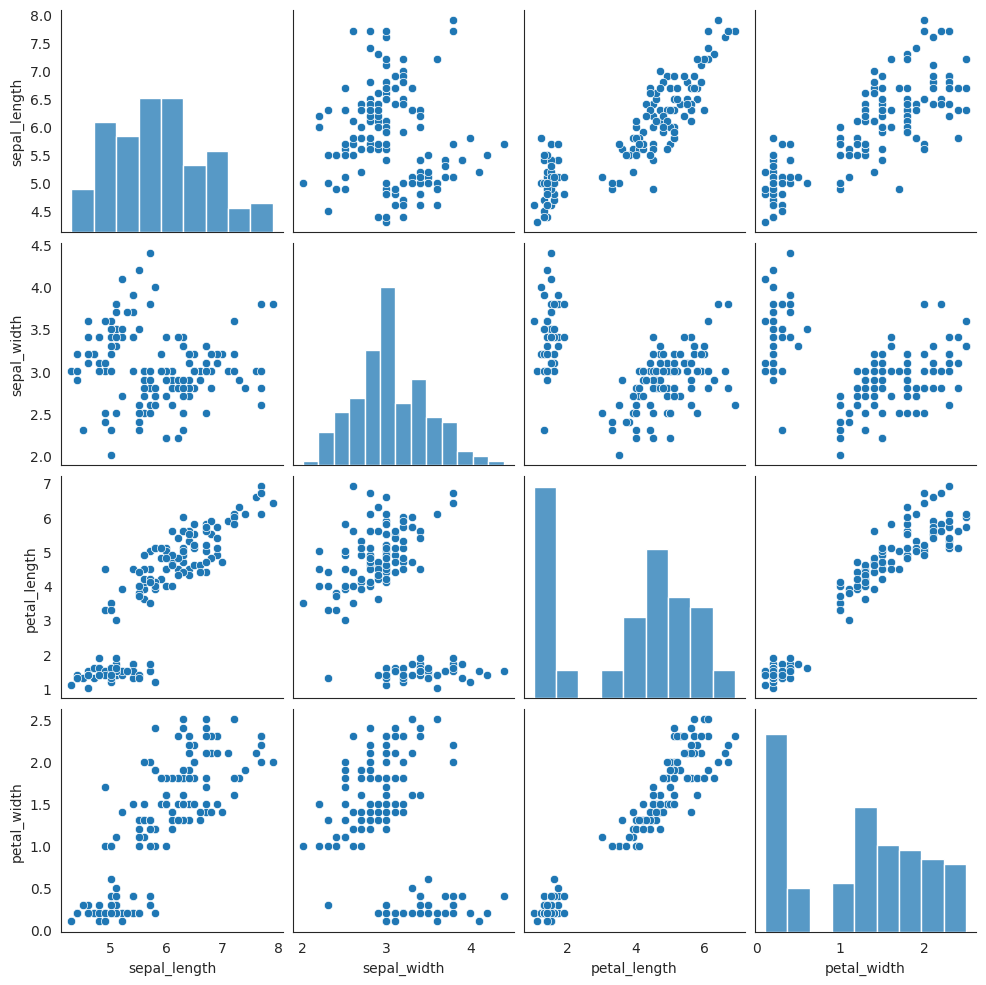

In [29]:
sns.pairplot(iris)

By using colors, you can get a much more useful plot.

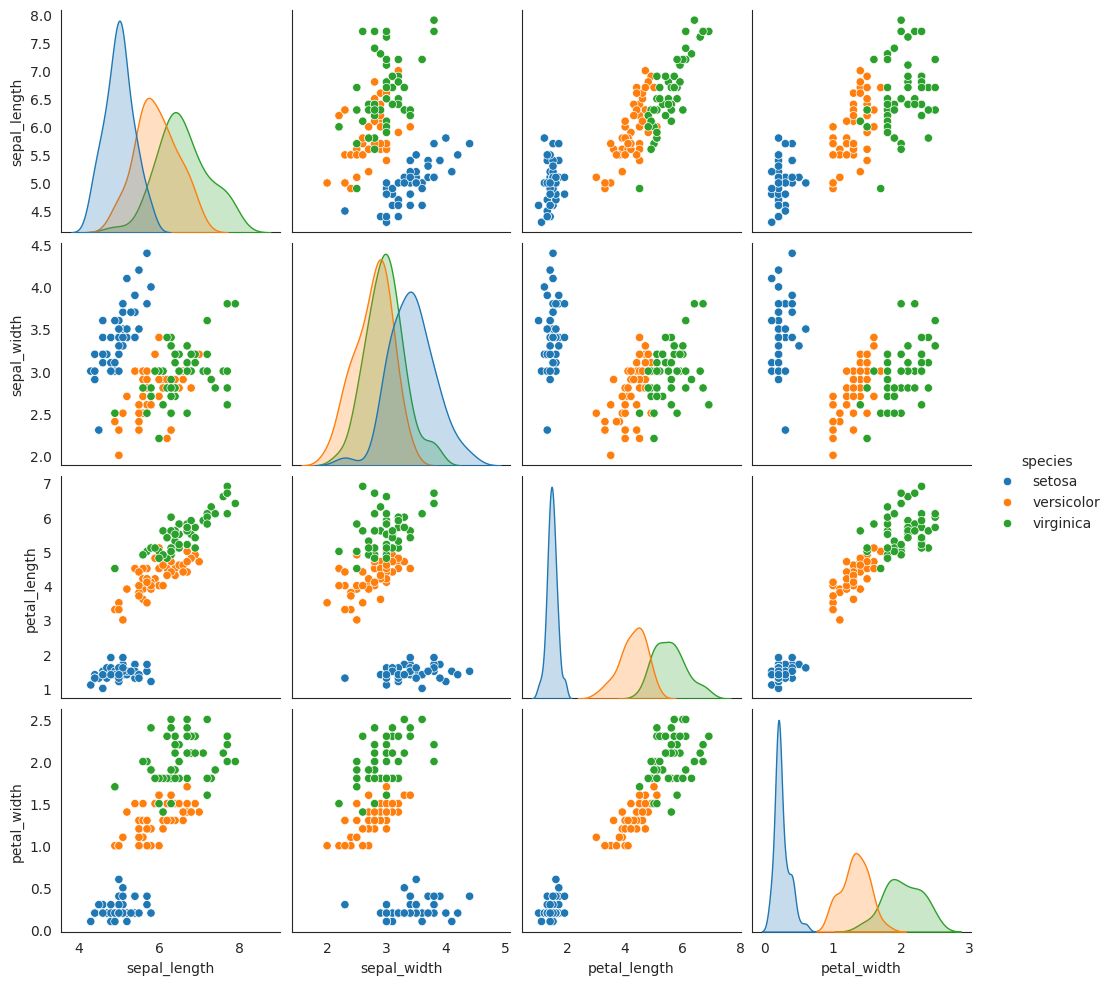

In [30]:
sns.pairplot(iris, hue='species')

Seaborn also lets us to specify what to put in the diagonal. When `hue` is used, it defaults to KDE plot. We can change it back to histogram. See: https://seaborn.pydata.org/generated/seaborn.pairplot.html

**Q: draw a pairplot with hue and histogram on the diagonal**

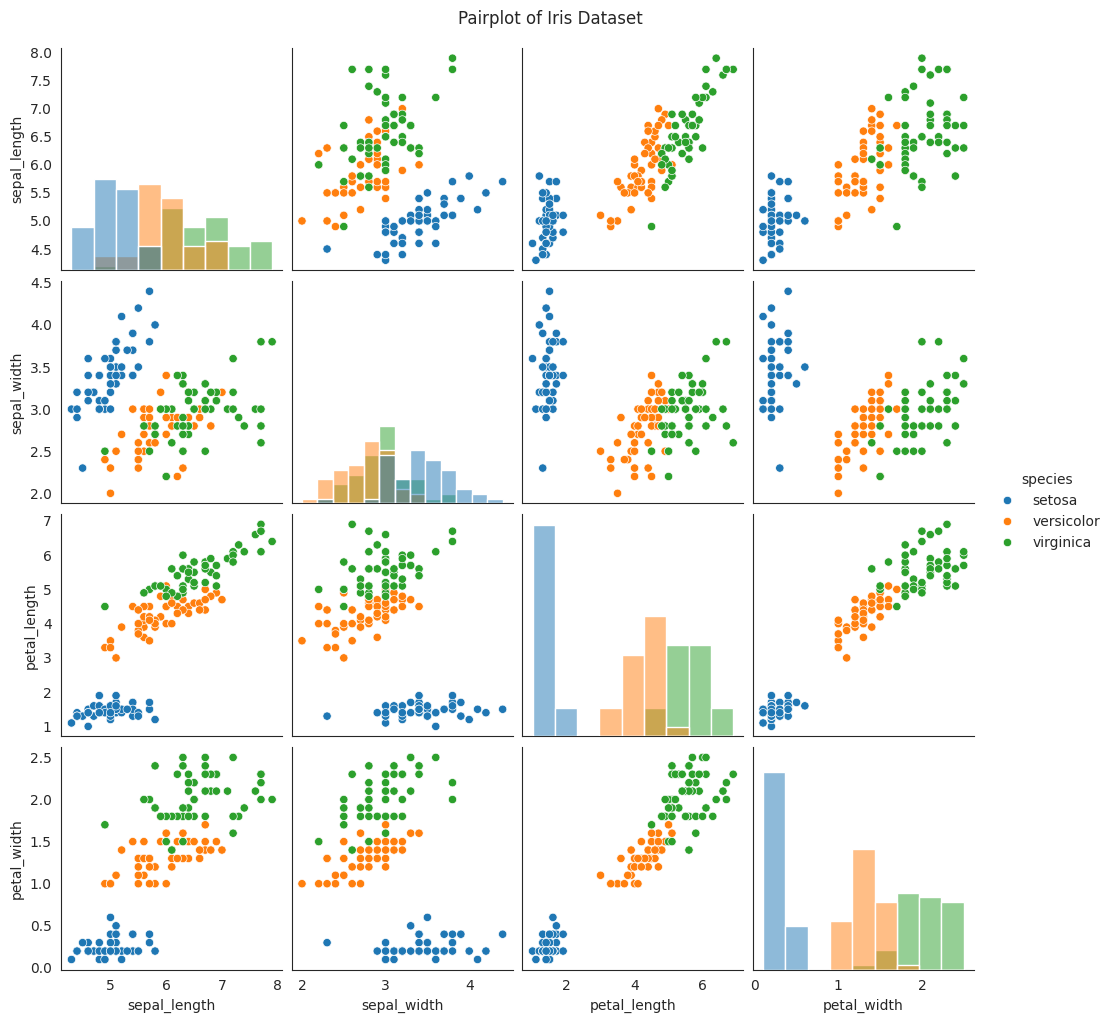

In [31]:
# YOUR SOLUTION HERE
sns.pairplot(iris, hue="species", diag_kind="hist")
plt.suptitle("Pairplot of Iris Dataset", y=1.02)
plt.show()


We can use altair to create an interactive scatterplot matrix. Can you create a scatterplot matrix of iris dataset by consulting https://altair-viz.github.io/gallery/scatter_matrix.html?

**Q: Draw an interactive scatterplot matrix for iris dataset in altair**

In [32]:
# YOUR SOLUTION HERE
import altair as alt
from vega_datasets import data

# Load Iris dataset
iris = sns.load_dataset('iris')

# Create an interactive scatterplot matrix
chart = alt.Chart(iris).mark_point().encode(
    alt.X(alt.repeat("column"), type='quantitative'),
    alt.Y(alt.repeat("row"), type='quantitative'),
    color='species'
).properties(
    width=150,
    height=150
).repeat(
    row=['sepal_length', 'sepal_width', 'petal_length', 'petal_width'],
    column=['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
).interactive()

chart


alt.RepeatChart(...)

## Parallel coordinates

Another useful visualization you can create with not-so-high-dimensional datasets is parallel coordinate visualization. Actually pandas supports parallel coordinate plots as well as "Andrews curve" (you can think of it as a smooth version of parallel coordinate.

- https://pandas.pydata.org/pandas-docs/stable/user_guide/visualization.html#parallel-coordinates
- https://pandas.pydata.org/pandas-docs/stable/user_guide/visualization.html#andrews-curves


**Q: Can you draw a parallel coordinate plot and a andrews curve plot of iris dataset?**  (I'm using `viridis` and `winter` colormap btw)


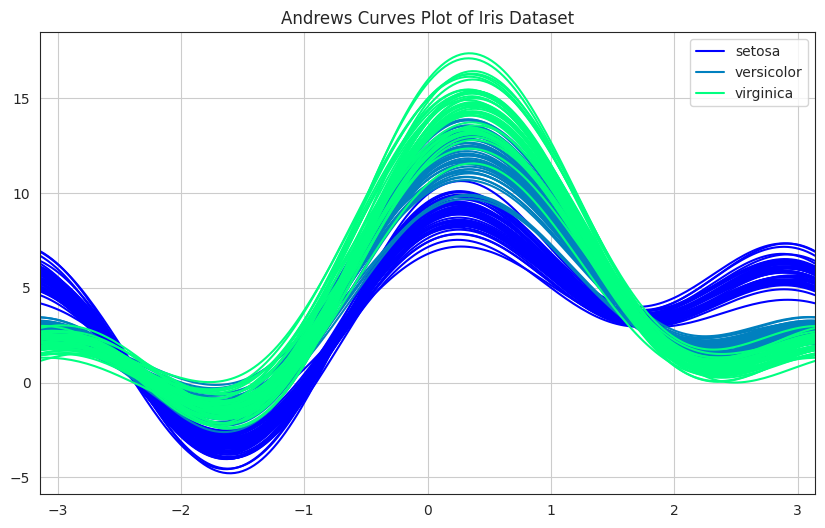

In [33]:
# YOUR SOLUTION HERE
from pandas.plotting import andrews_curves

plt.figure(figsize=(10, 6))
andrews_curves(iris, class_column='species', colormap='winter')
plt.title("Andrews Curves Plot of Iris Dataset")
plt.grid(True)
plt.show()


<Axes: >

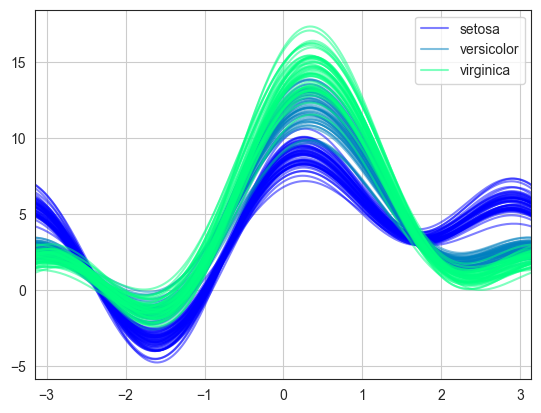

In [ ]:
# YOUR SOLUTION HERE

We can also use altair.

In [34]:
iris_transformed = iris.reset_index().melt(['species', 'index'])
alt.Chart(iris_transformed).mark_line().encode(
    x='variable:N',
    y='value:Q',
    color='species:N',
    detail='index:N',
    opacity=alt.value(0.5),
).properties(width=500)

alt.Chart(...)

**Q: can you explain how `iris_transformed` is different from the original `iris` dataset and why do we need to transform in this way?**

# YOUR SOLUTION HERE

`iris_transformed` is a new version of the original `iris` dataset where the four original features
(`sepal_length`, `sepal_width`, `petal_length`, `petal_width`) have been replaced by two new
features called principal components.

These components are linear combinations of the original features, chosen in a way that:
- The first component captures the maximum possible variance in the data.
- The second component captures the next highest variance, orthogonal to the first.

We transform the data this way because PCA helps us:
- Reduce dimensionality while preserving as much variance as possible.
- Visualize high-dimensional data in 2D or 3D plots.
- Eliminate redundancy and highlight the most informative aspects of the data.

This is important because visualizing all original dimensions may not be possible or useful,
and PCA allows us to better understand the underlying structure.


## PCA

The [principal component analysis (PCA)](http://setosa.io/ev/principal-component-analysis/) is the most basic dimensionality reduction method. For example, in the Iris dataset we have four variables (`sepal_length`, `sepal_width`, `petal_length`, `petal_width`). If we can reduce the number of variables to two, then we can easily visualize them in two dimensions.

PCA is already implemented in the [scikit-learn](http://scikit-learn.org/stable/) package, a machine learning library in Python, which should have been included in Anaconda. If you don't have it, install it. Depending on your environment manager, you can use the following commands.

```sh
uv add scikit-learn
```

or

```sh
conda install scikit-learn
```

or

```sh
pip install scikit-learn
```

In [ ]:
iris.head(2)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa


This is a four dimensional data. To run the PCA we want to isolate only the numerical columns.

In [35]:
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
iris_only_features = iris[features]
iris_only_features.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Data Preprocessing: The Importance of Standardization

Before applying PCA, let's standardize the data. PCA is sensitive to the scale of features because it finds directions of maximum variance. Features with larger scales will dominate the principal components.

**Example**: If one feature ranges from 0-1000 and another from 0-1, PCA will be biased toward the first feature simply due to its scale, not its actual importance.

Let's check the scales of our iris features:

In [36]:
iris_only_features.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Q: can you now standardize this feature matrix?**

In [37]:
# Drop species column and extract features
X = iris.drop('species', axis=1)

# Standardize the feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert to DataFrame for easier viewing
iris_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Show summary stats
print("\nFeature statistics after standardization:")
print(iris_scaled_df.describe())



Feature statistics after standardization:
       sepal_length   sepal_width  petal_length   petal_width
count  1.500000e+02  1.500000e+02  1.500000e+02  1.500000e+02
mean  -4.736952e-16 -7.815970e-16 -4.263256e-16 -4.736952e-16
std    1.003350e+00  1.003350e+00  1.003350e+00  1.003350e+00
min   -1.870024e+00 -2.433947e+00 -1.567576e+00 -1.447076e+00
25%   -9.006812e-01 -5.923730e-01 -1.226552e+00 -1.183812e+00
50%   -5.250608e-02 -1.319795e-01  3.364776e-01  1.325097e-01
75%    6.745011e-01  5.586108e-01  7.627583e-01  7.906707e-01
max    2.492019e+00  3.090775e+00  1.785832e+00  1.712096e+00


In [44]:
from sklearn.decomposition import PCA

# Create PCA object
pca = PCA(n_components=2)

# Fit and transform the scaled data
iris_transformed = pca.fit_transform(X_scaled)

# Convert to DataFrame
iris_transformed_df = pd.DataFrame(iris_transformed, columns=['PC1', 'PC2'])
iris_transformed_df['species'] = iris['species']  # add labels back

# Show first few rows
iris_transformed_df.head()


,PC1,PC2,species
0,-2.264703,0.480027,setosa
1,-2.080961,-0.674134,setosa
2,-2.364229,-0.341908,setosa
3,-2.299384,-0.597395,setosa
4,-2.389842,0.646835,setosa


We should first create a PCA object and specify the number of components to obtain. Note that you can obtain more than two principal components.

In [38]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2) # set the number of components to 2

Now you can run `fit()` method to identify principal components.

In [40]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)  # set number of components to 2
pca_iris_fitted = pca.fit(X_scaled)


An important set of numbers that you want to look at is the *explained variance ratio*.

In [41]:
pca_iris_fitted.explained_variance_ratio_

array([0.72962445, 0.22850762])

It tells you how much of the variance in the original dataset is explained by the principal components that you obtained. It seems like the first two components capture more than 95% of the variance in original dataset. This means that the PCA is very effective on this dataset and just using two principal components is a very good approximation to use all dimensions. Now you can use the result to transform the original dataset.

In [43]:
iris_pca = pca.fit_transform(X_scaled)


A convenient way to do both fitting and transforming is

You can see that this transformed matrix has two columns. Each column corresponds to the "loading" for one of the principal components.

In [48]:
iris_pca_df = pd.DataFrame(data=iris_pca, columns=['PC1', 'PC2'])
iris_pca_df.head()

,PC1,PC2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


Let's add the species information to the dataframe.

**Q: add species column to `iris_pca_df`.**

In [49]:
# YOUR SOLUTION HERE
iris_pca_df['species'] = iris['species']


Now we can produce a scatterplot based on the two principal components. Well, let's just draw a pairplot.

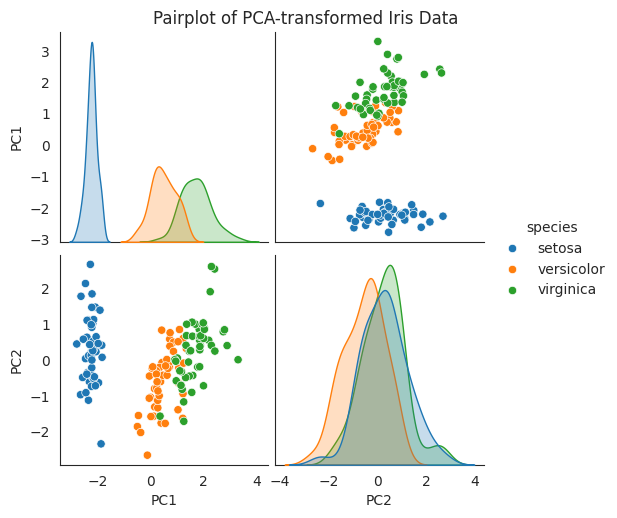

In [50]:
# YOUR SOLUTION HERE
sns.pairplot(iris_pca_df, hue="species")
plt.suptitle("Pairplot of PCA-transformed Iris Data", y=1.02)
plt.show()


The PC1 seems to capture inter-species variation while PC2 seems to capture intra-species variation. 🧐 Interesting!

### PCA with faces

Let's play with PCA with some faces. 🙄😬🤓

In [51]:
from sklearn.datasets import fetch_olivetti_faces

dataset = fetch_olivetti_faces(shuffle=True)
faces = dataset.data

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data


In [52]:
n_samples, n_features = faces.shape
print(n_samples)
print(n_features)

400
4096


So, this dataset contains 400 faces, and each of them has 4096 features (=pixels). Let's look at the first face:

In [53]:
print(faces[0].shape)
faces[0]

(4096,)


array([0.6694215 , 0.6363636 , 0.6487603 , ..., 0.08677686, 0.08264463,
       0.07438017], dtype=float32)

It's an one-dimensional array with 4096 numbers. But a face should be a two-dimensional picture, right? Use `numpy`'s [**`reshape()`**](http://docs.scipy.org/doc/numpy/reference/generated/numpy.reshape.html) function as well as `matplotlib`'s [**`imshow()`**](http://matplotlib.org/api/pyplot_api.html#matplotlib.pyplot.imshow) function, transform this one-dimensional array into an appropriate 2-D matrix and draw it to show the face. You probably want to use `plt.cm.gray` as colormap.

Be sure to play with different shapes (e.g. 2 x 2048, 1024 x 4, 128 x 32, and so on) and think about why they look like what they look like. What is the right shape of the array?

**Q: reshape the one-dimensional array into an appropriate two dimensional array and show the face**

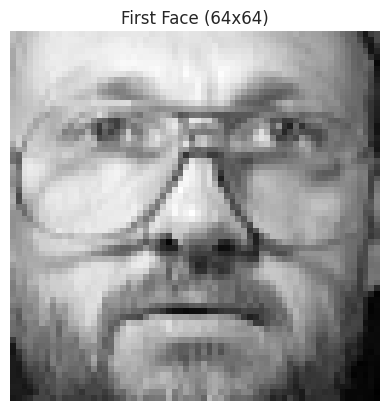

In [61]:
# TODO: draw faces[0] with various shapes. Find the correct dimension.
# image_shape = (xx, yy)

# YOUR SOLUTION HERE

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_olivetti_faces

# Load dataset
dataset = fetch_olivetti_faces(shuffle=True)
faces = dataset.data

# Reshape the first face
image_shape = (64, 64)
face_reshaped = faces[0].reshape(image_shape)

# Show the face
plt.imshow(face_reshaped, cmap=plt.cm.gray)
plt.title("First Face (64x64)")
plt.axis('off')
plt.show()


In [60]:
image_shape = (64, 64)


Let's perform PCA on this dataset.

In [55]:
from sklearn.decomposition import PCA

Set the number of components to 6:

In [56]:
n_components=6
pca = PCA(n_components=n_components)

Fit the faces data:

In [57]:
pca.fit(faces)

PCA(n_components=6)

PCA has an attribute called `components_`. It is a $\text{n-components} \times \text{n-features}$ matrix, in our case $6 \times 4096$. Each row is a component.

In [58]:
pca.components_

array([[ 0.00419113,  0.00710947,  0.00933605, ..., -0.00018512,
        -0.00337962, -0.00318823],
       [ 0.02859141,  0.03328844,  0.03784652, ..., -0.02962782,
        -0.02721299, -0.024889  ],
       [ 0.00135686, -0.00032583, -0.00019799, ..., -0.01541365,
        -0.01370979, -0.01188341],
       [ 0.00112418, -0.00179029, -0.01168222, ...,  0.02942997,
         0.02781916,  0.02521851],
       [ 0.02384015,  0.02358716,  0.0221572 , ...,  0.04243749,
         0.04007317,  0.04110229],
       [ 0.02910317,  0.03130735,  0.02877938, ..., -0.0163579 ,
        -0.01637343, -0.01490849]], dtype=float32)

In [59]:
pca.components_.shape

(6, 4096)

We can display the 6 components as images:

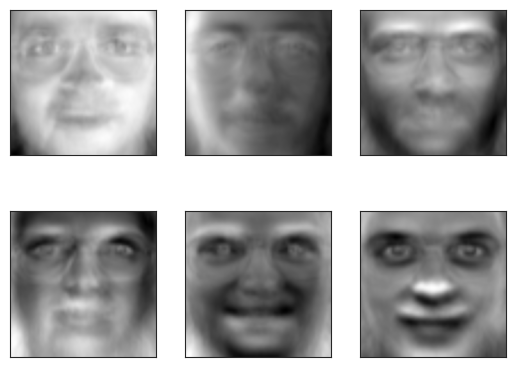

In [62]:
# use the `image_shape` that you defined in the previous question.

for i, comp in enumerate(pca.components_, 1):
    plt.subplot(2, 3, i)
    plt.imshow(comp.reshape(image_shape), cmap=plt.cm.gray, interpolation='gaussian')
    plt.xticks(())
    plt.yticks(())

😱 Looks a bit scary...

They are the "principal faces", which means that, by adding up these images with some appropriate weights, we can get a close approximation of the 400 images in the dataset!

We can get the coordinates of the 6 components to understand how each face is composed with the components.

In [63]:
faces_pca_transformed = pca.transform(faces)

In [64]:
faces_pca_transformed.shape

(400, 6)

`faces_r` is a $400 \times 6$ matrix. Each row corresponds to one face, containing the coordinates of the 6 components. For instance, the coordinates for the first face is

In [65]:
faces_pca_transformed[0]

array([-0.8157959 ,  4.144031  ,  2.4832609 , -0.9030869 , -0.8314333 ,
        0.88623273], dtype=float32)

It seems that the second component (with coordinate 4.14403343) contributes the most to the first face. Let's display them together and see how similar they are:

([], [])

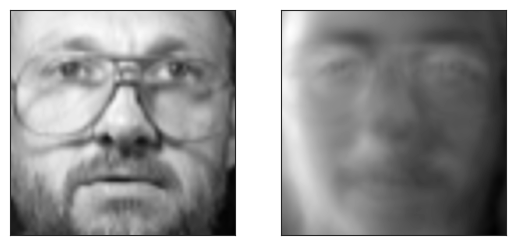

In [66]:
# display the first face image
plt.subplot(1, 2, 1)
plt.imshow(faces[0].reshape(image_shape), cmap=plt.cm.gray, interpolation='gaussian')
plt.xticks(())
plt.yticks(())

# display the second component
plt.subplot(1, 2, 2)
plt.imshow(pca.components_[1].reshape(image_shape), cmap=plt.cm.gray, interpolation='gaussian')
plt.xticks(())
plt.yticks(())

We can display the composition of faces in an "equation" style:

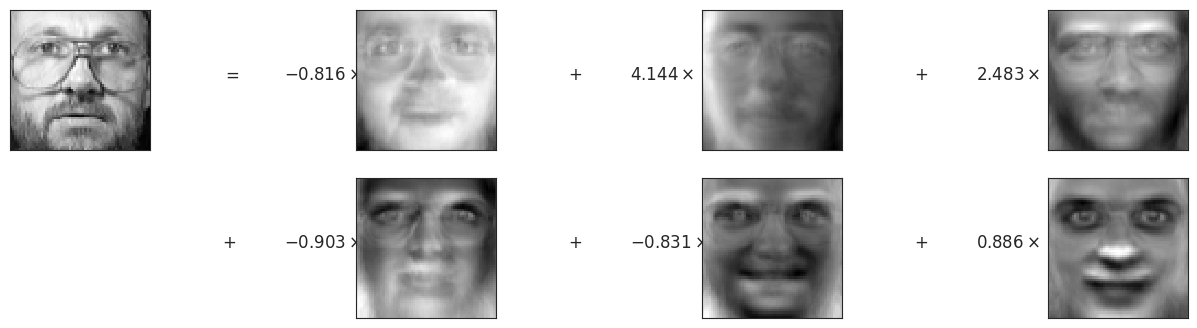

In [67]:
from matplotlib import gridspec

def display_image(ax, image):
    ax.imshow(image, cmap=plt.cm.gray, interpolation='nearest')
    ax.set_xticks(())
    ax.set_yticks(())

def display_text(ax, text):
    ax.text(.5, .5, text, size=12)
    ax.axis('off')

face_idx = 0

plt.figure(figsize=(16,4))
gs = gridspec.GridSpec(2, 10, width_ratios=[5,1,1,5,1,1,5,1,1,5])

# display the face
ax = plt.subplot(gs[0])
display_image(ax, faces[face_idx].reshape(image_shape))

# display the equal sign
ax = plt.subplot(gs[1])
display_text(ax, r'$=$')

# display the 6 coordinates
for coord_i, gs_i in enumerate( [2,5,8,12,15,18] ):
    ax = plt.subplot(gs[gs_i])
    display_text( ax, r'$%.3f \times $' % faces_pca_transformed[face_idx][coord_i] )

# display the 6 components
for comp_i, gs_i in enumerate( [3,6,9,13,16,19] ):
    ax = plt.subplot(gs[gs_i])
    display_image( ax, pca.components_[comp_i].reshape(image_shape) )

# display the plus sign
for gs_i in [4,7,11,14,17]:
    ax = plt.subplot(gs[gs_i])
    display_text(ax, r'$+$')

We can directly see the results of this addition.

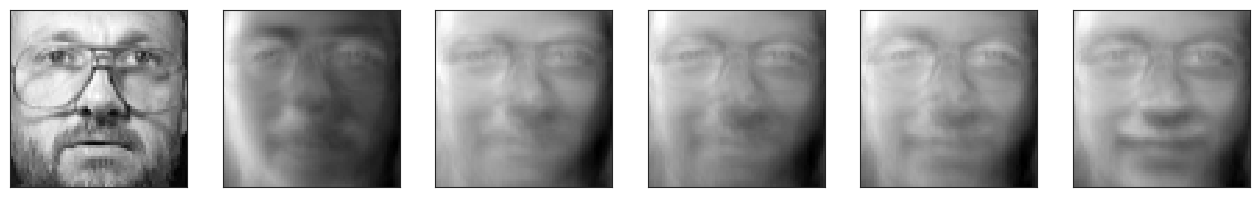

In [68]:
f, axes = plt.subplots(1, 6, figsize=(16,4))

faceid = 0

constructed_faces = []
for i in range(2, 10):
    constructed_faces.append(np.dot(faces_pca_transformed[faceid][:i], pca.components_[:i]))

# the face that we want to construct.
display_image(axes[0], faces[0].reshape(image_shape))

for idx, ax in enumerate(axes[1:]):
    display_image(ax, constructed_faces[idx].reshape(image_shape))

It becomes more and more real, although quite far with only several components.

## NMF

There is another pretty cool dimensionality reduction method called NMF (Non-negative matrix factorization). It is widely used in many domains, such as identifying topics in documents, identifying key components in images, and so on. The key idea is by forcing every element in the decomposed matrices positive, NMF breaks something into **parts** that we can add together.

**Q: fit the faces data with NMF, set the number of iterations higher than default**


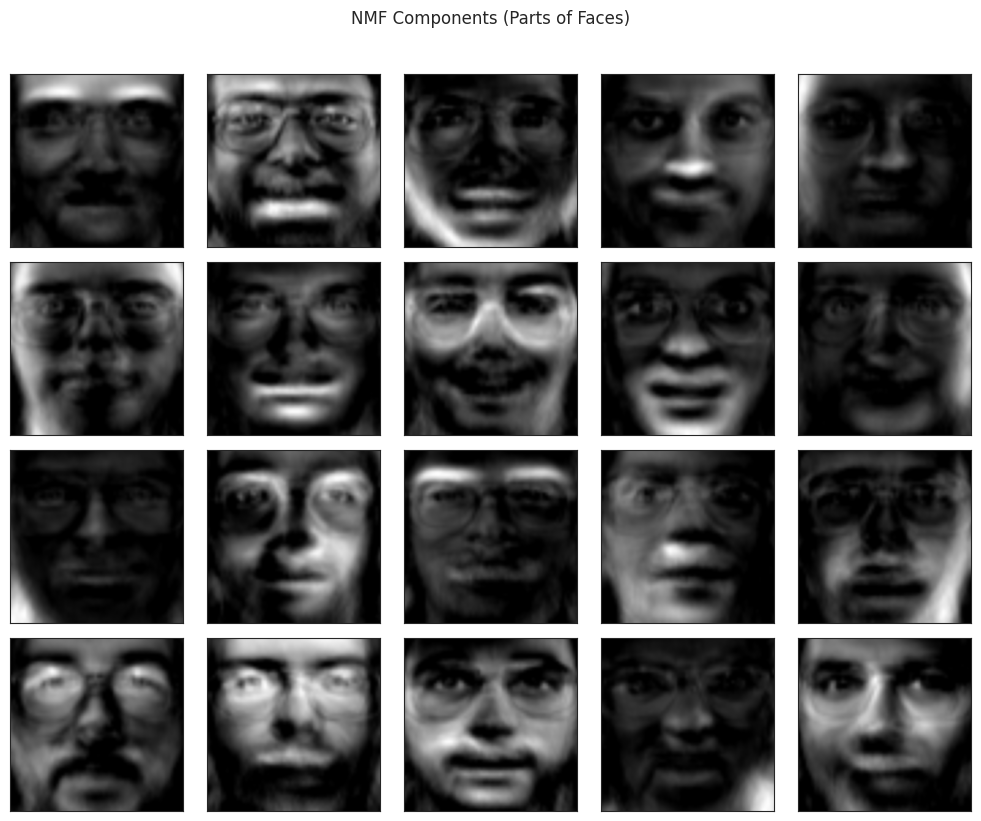

In [70]:
from sklearn.decomposition import NMF

n_components = 20
MAX_ITER = 10000

# Fit NMF
nmf = NMF(n_components=n_components, max_iter=MAX_ITER, init='random', random_state=0)
nmf_fitted = nmf.fit(faces)

# Display components
plt.figure(figsize=(10, 8))
for i, comp in enumerate(nmf_fitted.components_, 1):
    plt.subplot(4, 5, i)
    plt.imshow(comp.reshape(image_shape), cmap=plt.cm.gray, interpolation='gaussian')
    plt.xticks(())
    plt.yticks(())
plt.suptitle("NMF Components (Parts of Faces)", y=1.02)
plt.tight_layout()
plt.show()


As you can see here, each 'component' of NMF picks up a certain part of the face (light area), such as eyes, chin, nose, and so on. Very cool.

In [71]:
faces_nmf_tranformed = nmf_fitted.transform(faces)

In [72]:
faces_nmf_tranformed[0]

array([0.9719908 , 0.45884892, 0.1184555 , 0.11860947, 0.34566432,
       0.05976183, 0.10249256, 0.02044718, 0.29018298, 0.03260367,
       0.02624408, 0.03298584, 0.33418837, 0.04570183, 0.15617113,
       0.6430138 , 0.        , 0.262346  , 0.        , 0.35976657],
      dtype=float32)

Can you show the reconstructed faces using the first n components, as we did for the PCA?

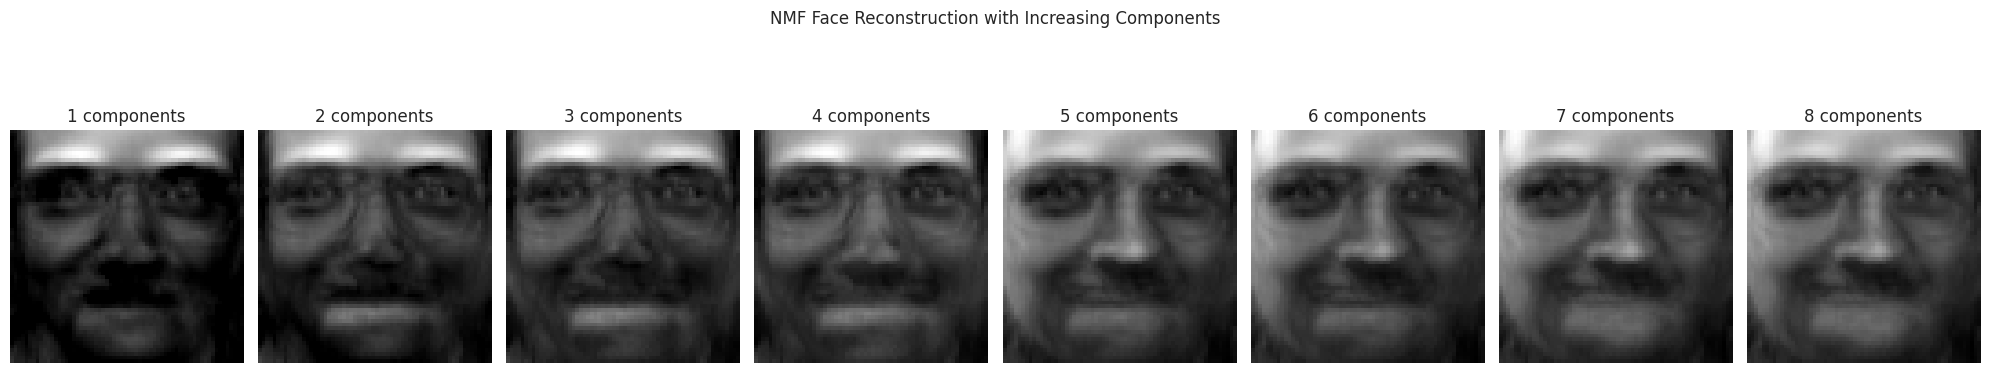

In [76]:
import numpy as np
import matplotlib.pyplot as plt

# Select face to reconstruct
faceid = 0
f, axes = plt.subplots(1, 8, figsize=(20, 4))
constructed_faces = []

# Reconstruct face using first 1 to 8 NMF components
for i in range(1, 9):
    # Use only the first i components
    W = nmf_fitted.transform(faces[[faceid]])[:, :i]  # weights for first i components
    H = nmf_fitted.components_[:i, :]                 # first i components

    # Reconstruct the face
    reconstructed = np.dot(W, H)
    constructed_faces.append(reconstructed.reshape(image_shape))

    # Plot reconstruction
    axes[i - 1].imshow(reconstructed.reshape(image_shape), cmap=plt.cm.gray)
    axes[i - 1].set_title(f"{i} components")
    axes[i - 1].axis('off')

plt.suptitle("NMF Face Reconstruction with Increasing Components", y=1.05)
plt.tight_layout()
plt.show()


Unlike PCA that keeps superposing positive and negative images, NMF tends to gradually add multiple parts to the image. This is why it is widely used for many decomposing tasks such as detecting topics from documents.

## t-SNE, Isomap, and MDS

Isomap, t-SNE, and MDS are nonlinear dimensionality reduction methods. Isomap preserves only the local relationships, MDS tries to preserve everything, and t-SNE is more flexible. t-SNE is very popular especially in machine learning.

Let's try t-SNE out with the iris data.

**Q: Fit-transform the iris data with t-SNE and create a scatterplot of it.**

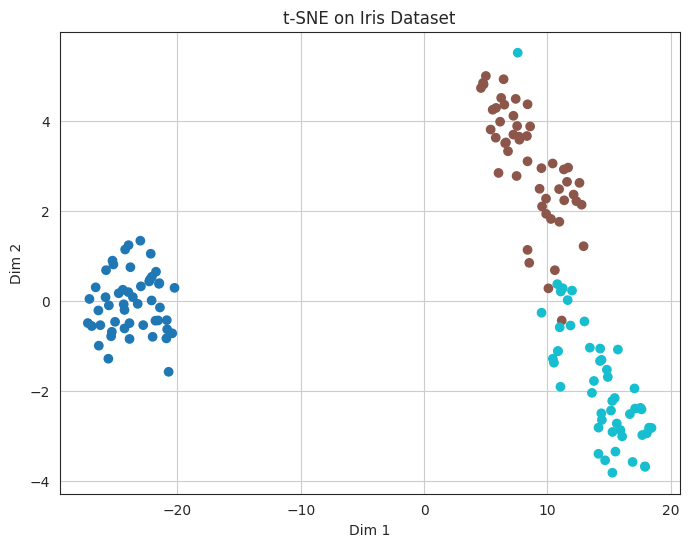

In [74]:
from sklearn.manifold import TSNE
from sklearn.manifold import Isomap
from sklearn.manifold import MDS
from sklearn.datasets import load_iris

# YOUR SOLUTION HERE
# Load the iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Fit t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

# Plot t-SNE results
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='tab10')
plt.title("t-SNE on Iris Dataset")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.grid(True)
plt.show()


The hyperparameter `perplexity` determines how to balance attention between local and global aspects of your data. Changing this parameter (default is 30) may cause drastic changes in the output. Play with multiple values of perplexity.

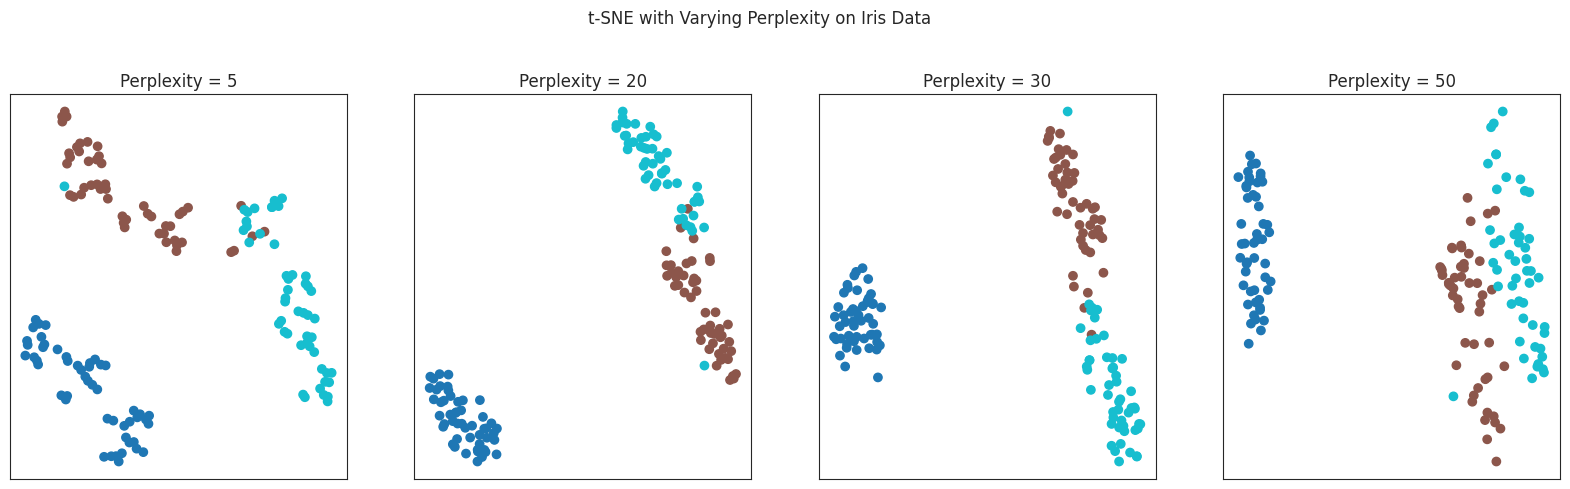

In [77]:
# YOUR SOLUTION HERE
iris = load_iris()
X = iris.data
y = iris.target

perplexities = [5, 20, 30, 50]
plt.figure(figsize=(20, 5))

for i, perplexity in enumerate(perplexities):
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42)
    X_tsne = tsne.fit_transform(X)

    plt.subplot(1, 4, i+1)
    scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='tab10')
    plt.title(f"Perplexity = {perplexity}")
    plt.xticks([])
    plt.yticks([])

plt.suptitle("t-SNE with Varying Perplexity on Iris Data", y=1.05)
plt.show()


If you want to learn more about t-SNE, play with https://distill.pub/2016/misread-tsne/ and https://experiments.withgoogle.com/visualizing-high-dimensional-space

### Visualizing the Digits dataset

This is a classic dataset of images of handwritten digits. It contains 1797 images with \(8*8=64\) pixels each.



In [78]:
from sklearn.datasets import load_digits

digits = load_digits()
digits.data.shape

(1797, 64)

digits.data stores the images:

In [79]:
digits.data[0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

and digits.target is the classes (or labels) that the images belong to. There are 10 classes in total.

In [80]:
digits.target

array([0, 1, 2, ..., 8, 9, 8])

**Q: use `imshow` to display the first image.**

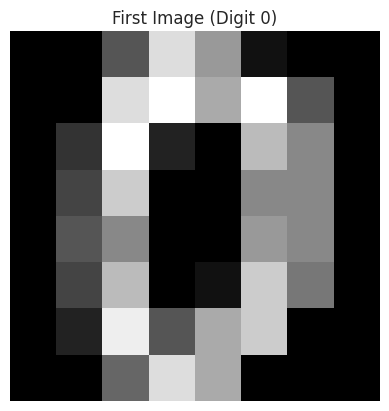

In [85]:
# YOUR SOLUTION HERE
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()
first_image = digits.images[0]  # already in (8, 8) shape

plt.imshow(first_image, cmap='gray')
plt.title("First Image (Digit 0)")
plt.axis('off')
plt.show()



Let's first reorder the data points according to the handwritten numbers. We can use [np.vstack](https://docs.scipy.org/doc/numpy/reference/generated/numpy.vstack.html) and [np.hstack](https://docs.scipy.org/doc/numpy/reference/generated/numpy.hstack.html).

In [86]:
X = np.vstack([digits.data[digits.target==i]
               for i in range(10)])
y = np.hstack([digits.target[digits.target==i]
               for i in range(10)])

Then initialize a tsne model. For the meaning of the parameters see [here](http://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html).

In [87]:
tsne = TSNE(n_components=2, init='pca', random_state=0)

Fit the model on the data.

In [88]:
digits_proj = tsne.fit_transform(X)

Plot the results. Seaborn's [hls](http://seaborn.pydata.org/generated/seaborn.hls_palette.html#seaborn.hls_palette) palatte provides evenly spaced colors in HLS hue space, we can divide it into 10 colors.

In [89]:
palette = np.array(sns.color_palette("hls", 10))

Make a scatter plot of the first component against the second component, with color based on the numbers.

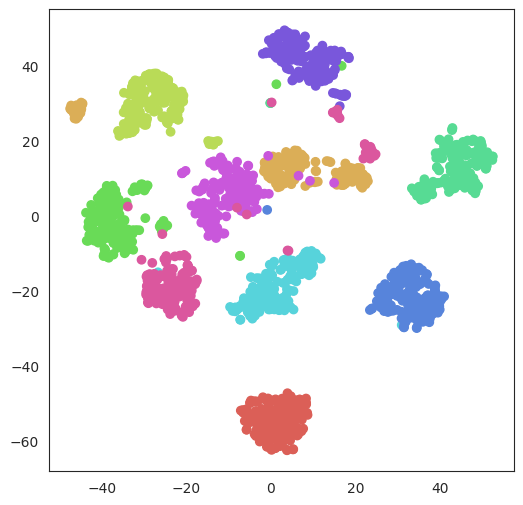

In [90]:
plt.figure(figsize = (6,6))
plt.scatter(digits_proj[:,0], digits_proj[:,1],c=palette[y])

We can add some text for each cluster. The place of the text can be the center of the cluster. We can use `np.median` to find the centers. To simplify things, we can make the code into a function.

In [91]:
def plot_scatter(projection):
    plt.figure(figsize = (6,6))
    plt.scatter(projection[:,0], projection[:,1],c=palette[y])
    for i in range(10):
        # Position of each label.
        xtext, ytext = np.median(projection[y == i, :], axis=0)
        txt = plt.text(xtext, ytext, str(i), fontsize=24)

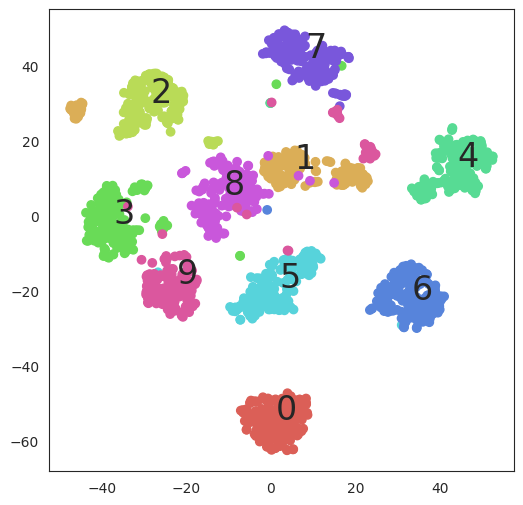

In [92]:
plot_scatter(digits_proj)

### Comparison with Isomap and MDS

We talked about MDS and Isomap in class as two other manifold learning methods. Sklearn also has implementations for this two algorithms: [MDS](http://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html) and [Isomap](http://scikit-learn.org/stable/modules/generated/sklearn.manifold.Isomap.html), so the usage is very similar. Examples for using this methods can be found [here](http://scikit-learn.org/stable/auto_examples/manifold/plot_lle_digits.html).

**Q: Can you make another two plots with these two methods? You only need to change the models and call the `plot_scatter` function.**

In [96]:
import matplotlib.pyplot as plt

def plot_scatter(X, y, title=""):
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.tab10, s=20)
    plt.title(title)
    plt.xlabel("Dim 1")
    plt.ylabel("Dim 2")
    plt.colorbar(scatter)
    plt.show()


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/usr/local/lib/python3.11/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


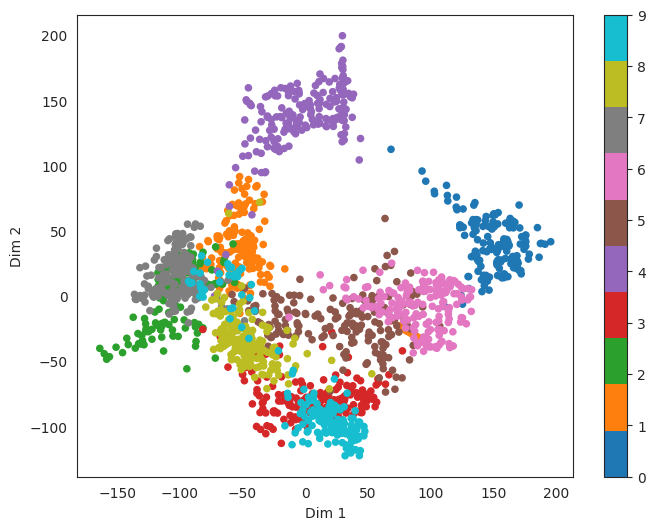

In [97]:
# ISOMAP
from sklearn.manifold import Isomap

# Fit and transform the data using Isomap
isomap = Isomap(n_components=2)
X_isomap = isomap.fit_transform(X)

# Plot the result
plot_scatter(X_isomap, y)

# YOUR SOLUTION HERE

In [100]:
import matplotlib.pyplot as plt

def plot_scatter(X, y, title=""):
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.tab10, s=20)
    plt.title(title)
    plt.xlabel("Dim 1")
    plt.ylabel("Dim 2")
    plt.colorbar(scatter)
    plt.show()


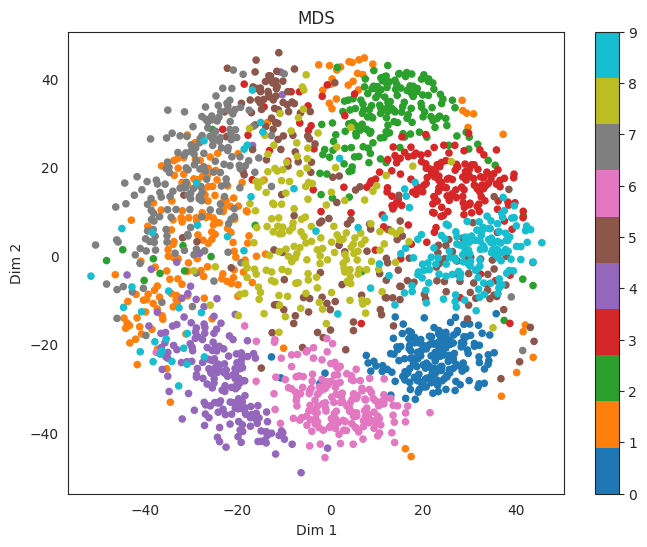

In [101]:
# MDS
# YOUR SOLUTION HERE
from sklearn.manifold import MDS

mds = MDS(n_components=2, random_state=42)
X_mds = mds.fit_transform(X)

plot_scatter(X_mds, y, title="MDS")



/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/usr/local/lib/python3.11/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/tmp/ipython-input-102-2197117343.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


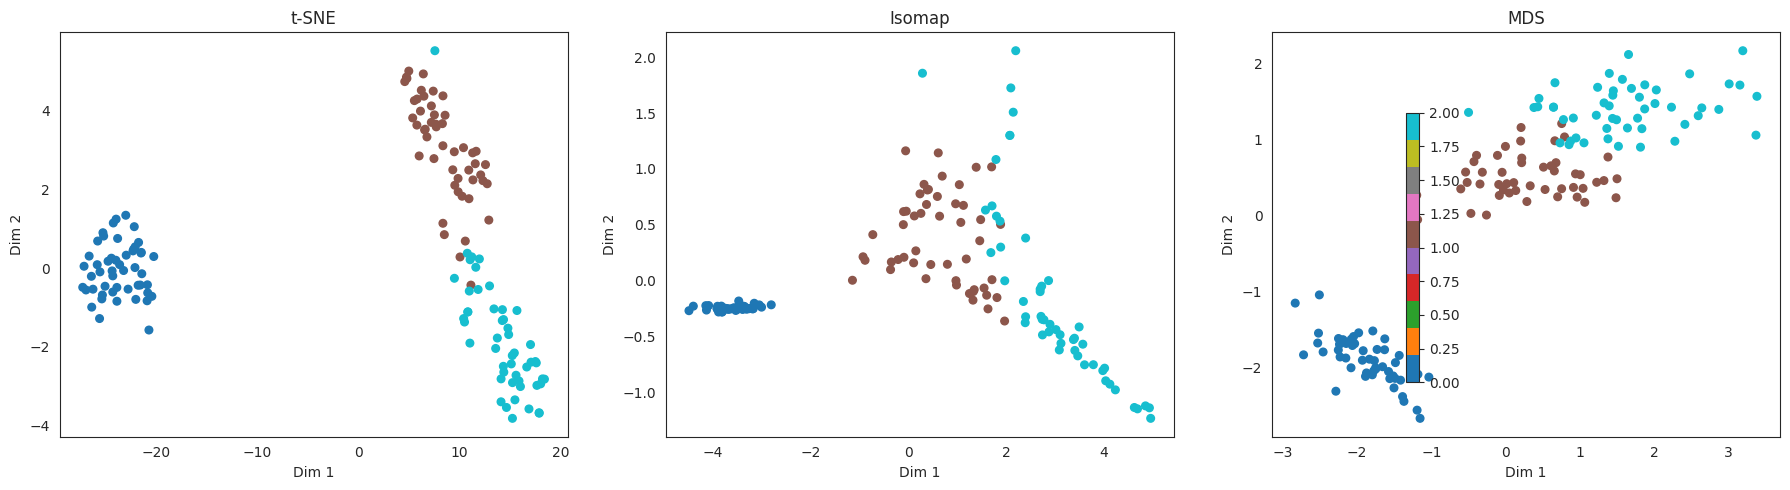

In [102]:
from sklearn.manifold import TSNE, Isomap, MDS
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

# Load data
iris = load_iris()
X = iris.data
y = iris.target

# Apply dimensionality reduction
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(X)
X_isomap = Isomap(n_components=2).fit_transform(X)
X_mds = MDS(n_components=2, random_state=42).fit_transform(X)

# Plot them side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

titles = ["t-SNE", "Isomap", "MDS"]
datasets = [X_tsne, X_isomap, X_mds]

for ax, data, title in zip(axes, datasets, titles):
    sc = ax.scatter(data[:, 0], data[:, 1], c=y, cmap=plt.cm.tab10, s=30)
    ax.set_title(title)
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")

fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.7)
plt.tight_layout()
plt.show()


(Optional) Feel free to try UMAP as well! It's a new dimensionality reduction method that is getting the most popular.